# RobustScaler vs StandardScaler при наличии выбросов

**Цель:** экспериментально проверить, как выбросы влияют на параметры масштабирования, преобразованные значения обычных объектов и качество модели KNN.

## 1. Теория

**StandardScaler** преобразует признак по формуле

$$z=\frac{x-\mu}{\sigma},$$

где $\mu$ — среднее, $\sigma$ — стандартное отклонение обучающей выборки. Эти оценки чувствительны к экстремальным значениям.

**RobustScaler** использует медиану и межквартильный размах:

$$z=\frac{x-\operatorname{median}(X)}{Q_{0.75}-Q_{0.25}}.$$

Медиана и квартили обычно меньше реагируют на немногочисленные экстремальные наблюдения. Однако выбросы не удаляются и после преобразования могут оставаться очень большими.

**Проверяем гипотезы:**
 1. параметры RobustScaler изменяются слабее при умеренном загрязнении;
 2. обычные наблюдения меньше смещаются относительно варианта без выбросов;
 3. качество KNN может зависеть от выбора скейлера, но победитель заранее неизвестен.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from IPython.display import display

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.grid': True, 'grid.alpha': 0.22})

## 2. Данные и корректная схема эксперимента

Создадим задачу бинарной классификации с четырьмя числовыми признаками разного масштаба. Разделим данные на train/test до масштабирования. Тест оставляем чистым и неизменным, чтобы сравнение моделей было честным. Во всех экспериментах будем изменять только обучающую выборку.

Для контролируемого эксперимента выбросы — это крупные добавочные значения в одном признаке выбранных объектов. Их доля: 0%, 5%, 10%, 20%. Для каждого уровня используем одни и те же индексы и величины при сравнении двух скейлеров.

In [ ]:
X, y = make_classification(
    n_samples=1200, n_features=4, n_informative=3, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.2, flip_y=0.03,
    random_state=RANDOM_STATE
)
feature_names = ['Признак 1', 'Признак 2', 'Признак 3', 'Признак 4']
X = X * np.array([1.0, 15.0, 0.2, 4.0])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
levels = [0, 5, 10, 20]

outlier_order = rng.permutation(len(X_train))
outlier_signs = rng.choice([-1, 1], size=len(X_train))
contamination_amplitude = 30 * X_train[:, 1].std()

def contaminate(X_base, percentage):
    X_dirty = X_base.copy()
    n = round(len(X_dirty) * percentage / 100)
    idx = outlier_order[:n]
    X_dirty[idx, 1] += outlier_signs[idx] * contamination_amplitude
    return X_dirty, idx

print('Train:', X_train.shape, 'Test:', X_test.shape)
display(pd.DataFrame(X_train, columns=feature_names).describe().round(2))

Train: (900, 4) Test: (300, 4)


,Признак 1,Признак 2,Признак 3,Признак 4
count,900.00,900.00,900.00,900.00
mean,1.24,-17.37,-0.01,0.37
std,0.94,13.58,0.20,6.22
min,-2.38,-72.74,-0.64,-18.06
25%,0.60,-25.41,-0.14,-4.36
50%,1.24,-17.63,0.00,0.89
75%,1.84,-9.12,0.12,5.04
max,4.47,28.46,0.65,14.78


## 3. Визуализация исходных данных и эффекта масштабирования

Посмотрим на второй признак, куда добавили 5% сильных выбросов. Сравним его значения в исходной шкале, после StandardScaler и после RobustScaler. Дополнительно выделим отдельными точками обычные наблюдения и выбросы.

**Важно для чтения графиков:** шкалы каждой строки отличаются; основной предмет сравнения — насколько сильно скучиваются обычные значения относительно экстремальных.

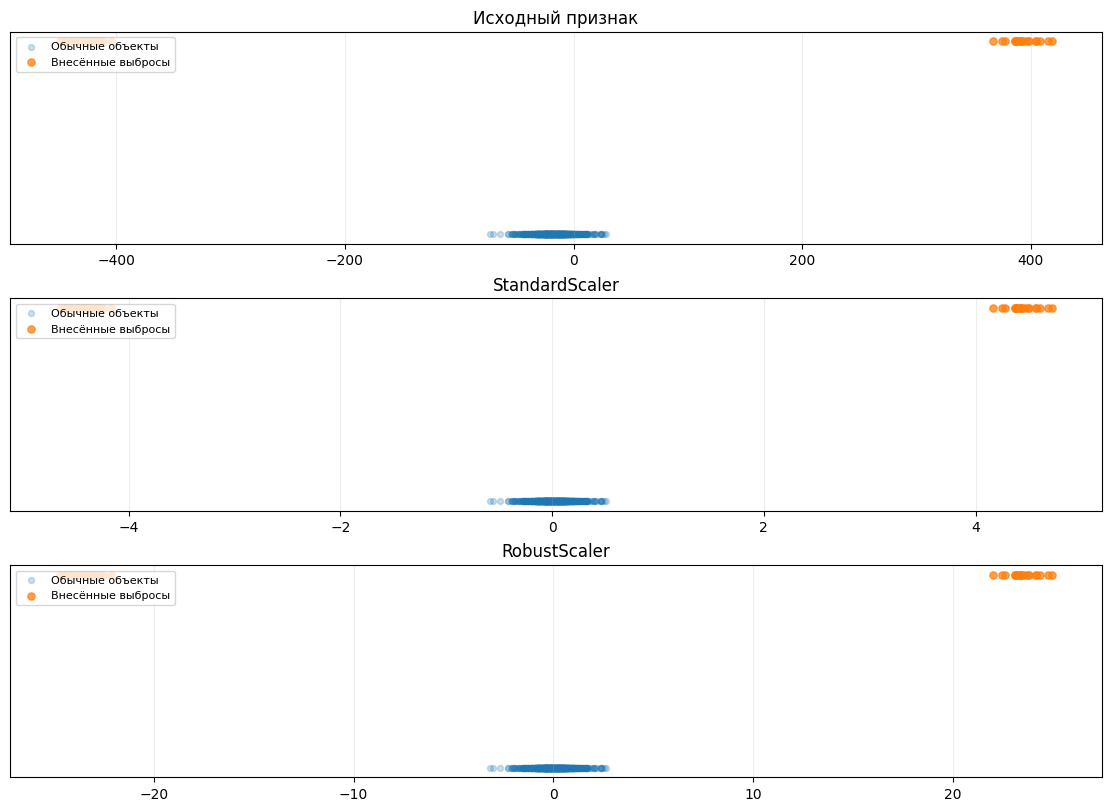

In [ ]:
X_dirty_5, outlier_idx_5 = contaminate(X_train, 5)
normal_mask = np.ones(len(X_train), dtype=bool)
normal_mask[outlier_idx_5] = False

transformed = {
    'Исходный признак': X_dirty_5[:, 1],
    'StandardScaler': StandardScaler().fit_transform(X_dirty_5)[:, 1],
    'RobustScaler': RobustScaler().fit_transform(X_dirty_5)[:, 1]
}
fig, axes = plt.subplots(3, 1, figsize=(11, 8), constrained_layout=True)
for ax, (label, values) in zip(axes, transformed.items()):
    ax.scatter(values[normal_mask], np.zeros(normal_mask.sum()), alpha=.24, s=18, label='Обычные объекты')
    ax.scatter(values[~normal_mask], np.zeros((~normal_mask).sum()) + .12,
               alpha=.75, s=27, label='Внесённые выбросы')
    ax.set_title(label)
    ax.set_yticks([])
    ax.legend(loc='upper left', fontsize=8)
plt.show()

**Промежуточный вывод.** Оба метода — линейное преобразование каждого признака: они не меняют порядок значений и не «вырезают» выбросы. Но выбор центра и масштаба различается. Поэтому корректнее измерить **устойчивость параметров** и **смещение обычных объектов**, а не судить только по длине оси на графике.

## 4. Изменение параметров масштабирования

Для каждого процента выбросов заново обучим оба скейлера на загрязнённой обучающей выборке. Запишем их параметры для второго признака: `center_` и `scale_` (для StandardScaler это mean/std, для RobustScaler — median/IQR). Посмотрим, насколько они отклоняются от значений при 0%.

,"Выбросы, %",Скейлер,Центр,Масштаб
0,0,StandardScaler,-17.372,13.569
1,0,RobustScaler,-17.625,16.294
2,5,StandardScaler,-18.729,92.621
3,5,RobustScaler,-17.666,17.478
4,10,StandardScaler,-20.991,129.827
5,10,RobustScaler,-17.925,18.801
6,20,StandardScaler,-27.323,182.433
7,20,RobustScaler,-18.362,21.869


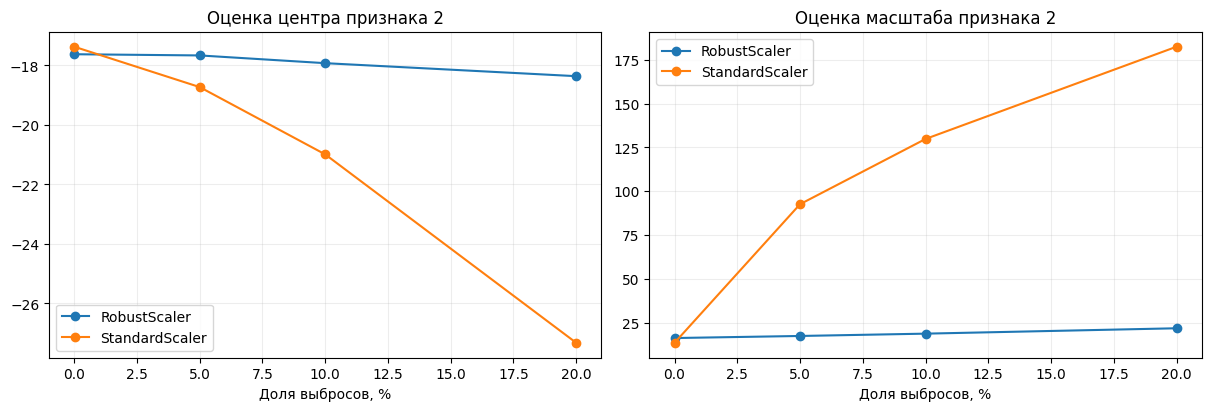

In [ ]:
parameter_rows = []
for level in levels:
    X_dirty, _ = contaminate(X_train, level)
    for name, scaler in [('StandardScaler', StandardScaler()), ('RobustScaler', RobustScaler())]:
        scaler.fit(X_dirty)
        center = scaler.mean_[1] if name == 'StandardScaler' else scaler.center_[1]
        parameter_rows.append({'Выбросы, %': level, 'Скейлер': name,
                               'Центр': center, 'Масштаб': scaler.scale_[1]})
parameters = pd.DataFrame(parameter_rows)
display(parameters.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, part in parameters.groupby('Скейлер'):
    axes[0].plot(part['Выбросы, %'], part['Центр'], marker='o', label=name)
    axes[1].plot(part['Выбросы, %'], part['Масштаб'], marker='o', label=name)
axes[0].set_title('Оценка центра признака 2')
axes[1].set_title('Оценка масштаба признака 2')
for ax in axes:
    ax.set_xlabel('Доля выбросов, %')
    ax.legend()
plt.show()

**Вывод по параметрам масштабирования.** При увеличении доли выбросов от 0 до 20% стандартное отклонение второго признака выросло с **13,569 до 182,433** (примерно в **13,4 раза**), а межквартильный размах — с **16,294 до 21,869** (примерно в **1,34 раза**). Среднее сместилось с −17,372 до −27,323, тогда как медиана — с −17,625 до −18,362. В этом эксперименте параметры `RobustScaler` действительно значительно устойчивее. Сопоставляем здесь **относительные изменения** масштаба каждого метода, а не абсолютные значения IQR и стандартного отклонения.

## 5. Насколько меняется представление обычных объектов?

Возьмём **одни и те же чистые тестовые объекты**. Сначала преобразуем их скейлером, обученным на чистой обучающей выборке — это эталон для данного метода. Затем сравним с преобразованием тех же объектов скейлером, обученным на загрязнённых данных.

Метрика — среднее абсолютное изменение преобразованных координат (MAE) по всем признакам тестовых объектов:

$$D = \frac{1}{nm}\sum_{i=1}^{n}\sum_{j=1}^{m}\left|T_{p}(x_{ij}) - T_0(x_{ij})\right|.$$

Чем меньше $D$, тем стабильнее преобразование **относительно собственного чистого базового варианта**. Сравнение между методами нужно трактовать осторожно: их выходные единицы отличаются.

,Скейлер,"Выбросы, %",Среднее абсолютное смещение
0,StandardScaler,0,0.0000
1,StandardScaler,5,0.1490
2,StandardScaler,10,0.1566
3,StandardScaler,20,0.1626
4,RobustScaler,0,0.0000
5,RobustScaler,5,0.0099
6,RobustScaler,10,0.0198
7,RobustScaler,20,0.0380


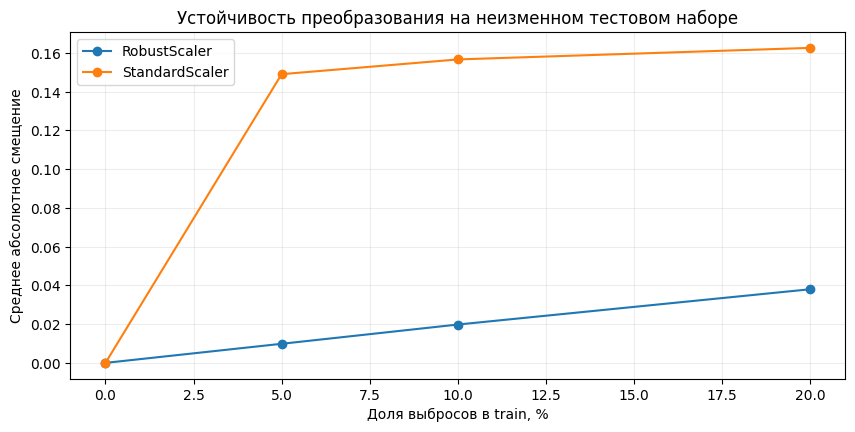

In [ ]:
stability_rows = []
for name, factory in [('StandardScaler', StandardScaler), ('RobustScaler', RobustScaler)]:
    baseline = factory().fit(X_train).transform(X_test)
    for level in levels:
        X_dirty, _ = contaminate(X_train, level)
        new_values = factory().fit(X_dirty).transform(X_test)
        stability_rows.append({'Скейлер': name, 'Выбросы, %': level,
                               'Среднее абсолютное смещение': np.mean(np.abs(new_values - baseline))})
stability = pd.DataFrame(stability_rows)
display(stability.round(4))
for name, part in stability.groupby('Скейлер'):
    plt.plot(part['Выбросы, %'], part['Среднее абсолютное смещение'], marker='o', label=name)
plt.xlabel('Доля выбросов в train, %')
plt.ylabel('Среднее абсолютное смещение')
plt.title('Устойчивость преобразования на неизменном тестовом наборе')
plt.legend()
plt.show()

**Вывод по устойчивости преобразования.** При 5% выбросов среднее абсолютное смещение одних и тех же чистых тестовых объектов составило **0,1490** после `StandardScaler` против **0,0099** после `RobustScaler`. При 20% — **0,1626** против **0,0380** соответственно. Это подтверждает более высокую стабильность `RobustScaler` в выбранном эксперименте. Однако значения разных скейлеров выражены в их собственных преобразованных шкалах, поэтому численное отношение этих величин нельзя трактовать как универсальное превосходство в фиксированное число раз.

## 6. Влияние на машинное обучение: KNN

KNN классифицирует объекты по близости к соседям. Изменение масштаба разных признаков изменяет вклад каждого признака в расстояние. Поэтому эксперимент показывает, как **весь пайплайн** (скейлер + KNN) реагирует на выбросы.

Для всех вариантов фиксируем `n_neighbors=7`; параметры модели не подбираем по тесту. Обучаем `Pipeline` только на train, оцениваем на одном и том же чистом test. Сравним `Accuracy` и `F1-score` (для положительного класса). Для ориентира добавим вариант без масштабирования.

,"Выбросы, %",Подход,Accuracy,F1
0,0,Без масштабирования,0.8867,0.8874
1,0,StandardScaler,0.9167,0.9135
2,0,RobustScaler,0.9200,0.9172
3,5,Без масштабирования,0.8867,0.8867
4,5,StandardScaler,0.8933,0.8919
5,5,RobustScaler,0.9167,0.9141
6,10,Без масштабирования,0.8833,0.8837
7,10,StandardScaler,0.9033,0.9037
8,10,RobustScaler,0.9100,0.9066
9,20,Без масштабирования,0.8867,0.8874


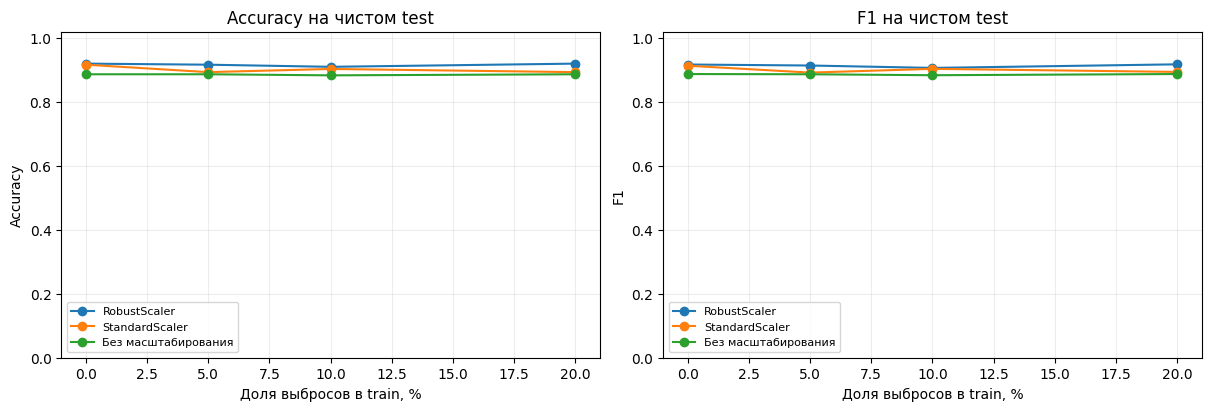

In [ ]:
model_rows = []
for level in levels:
    X_dirty, _ = contaminate(X_train, level)
    for name, scaler in [('Без масштабирования', 'passthrough'),
                         ('StandardScaler', StandardScaler()),
                         ('RobustScaler', RobustScaler())]:
        model = Pipeline([('scaler', scaler), ('knn', KNeighborsClassifier(n_neighbors=7))])
        model.fit(X_dirty, y_train)
        predictions = model.predict(X_test)
        model_rows.append({'Выбросы, %': level, 'Подход': name,
                           'Accuracy': accuracy_score(y_test, predictions),
                           'F1': f1_score(y_test, predictions)})
results = pd.DataFrame(model_rows)
display(results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, part in results.groupby('Подход'):
    for ax, metric in zip(axes, ['Accuracy', 'F1']):
        ax.plot(part['Выбросы, %'], part[metric], marker='o', label=name)
        ax.set_title(metric + ' на чистом test')
        ax.set_xlabel('Доля выбросов в train, %')
        ax.set_ylabel(metric)
        ax.set_ylim(0, 1.02)
        ax.legend(fontsize=8)
plt.show()

**Вывод по качеству KNN.** В этом разбиении `RobustScaler` показал лучший F1 при всех уровнях загрязнения. При **5% выбросов** F1 равен **0,9141** против **0,8919** у `StandardScaler` (преимущество около **2,2 процентного пункта**); при **20%** — **0,9178** против **0,8940** (около **2,4 п. п.**). Однако зависимость качества от доли выбросов **не монотонная**: на результат влияет, какие именно обучающие точки были изменены. Различия на одном разбиении не доказывают статистически значимого преимущества на любых данных.

## 7. Автоматически сформированные выводы по результатам

Следующие выводы рассчитываются из полученных таблиц.

In [ ]:
clean = parameters[parameters['Выбросы, %'] == 0].set_index('Скейлер')
worst = parameters[parameters['Выбросы, %'] == 20].set_index('Скейлер')
for name in ['StandardScaler', 'RobustScaler']:
    delta_center = abs(worst.loc[name, 'Центр'] - clean.loc[name, 'Центр'])
    delta_scale = abs(worst.loc[name, 'Масштаб'] - clean.loc[name, 'Масштаб'])
    print(f'{name}: |Δ центра| = {delta_center:.3f}; |Δ масштаба| = {delta_scale:.3f}')
print()
for level in levels:
    part = results[(results['Выбросы, %'] == level) & (results['Подход'] != 'Без масштабирования')]
    leader = part.loc[part['F1'].idxmax()]
    other = part.loc[part['F1'].idxmin()]
    diff = leader['F1'] - other['F1']
    if np.isclose(diff, 0):
        print(f'{level}% выбросов: оба скейлера дали одинаковый F1 = {leader["F1"]:.3f}.')
    else:
        print(f'{level}% выбросов: лучший F1 у {leader["Подход"]} '
              f'({leader["F1"]:.3f} против {other["F1"]:.3f}; разница {diff:.3f}).')

StandardScaler: |Δ центра| = 9.951; |Δ масштаба| = 168.864
RobustScaler: |Δ центра| = 0.737; |Δ масштаба| = 5.575

0% выбросов: лучший F1 у RobustScaler (0.917 против 0.913; разница 0.004).
5% выбросов: лучший F1 у RobustScaler (0.914 против 0.892; разница 0.022).
10% выбросов: лучший F1 у RobustScaler (0.907 против 0.904; разница 0.003).
20% выбросов: лучший F1 у RobustScaler (0.918 против 0.894; разница 0.024).


## 8. Итог

1. **StandardScaler** использует среднее и стандартное отклонение, поэтому экстремальные значения могут существенно менять преобразование *всех* наблюдений.
2. **RobustScaler** использует медиану и IQR; при небольшой доле сильных выбросов его параметры обычно стабильнее. При большом загрязнении устойчивость тоже ограничена.
3. **RobustScaler не удаляет выбросы**, а лишь по-другому вычисляет параметры масштабирования.
4. **Лучший результат в KNN определяется экспериментом**, а не одной формулой скейлера: важны распределение данных, информативность признаков, доля и расположение выбросов.
5. **Ограничения:** данные синтетические, загрязнение создано только в одном признаке, используется одна конфигурация KNN и одно train/test-разбиение. Для более сильного обобщения стоит повторить опыт на нескольких случайных seed и на реальном датасете.


**Результат конкретного эксперимента:** при 20% выбросов масштаб второго признака вырос в 13,4 раза у `StandardScaler` и в 1,34 раза у `RobustScaler`. На чистом тесте KNN получил F1 **0,8940** со `StandardScaler` и **0,9178** с `RobustScaler`. Эти числа относятся только к текущим синтетическим данным и фиксированному разбиению.